# Tile-coded SARSA and replacing traces

Official MountainCar needs momentum-building behavior. Eight tilings of normalized position and velocity produce sparse linear action values. Lambda zero and .9 compare trace propagation under a fixed episode budget; actual interaction counts differ and are recorded.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'src/decision_lab').is_dir()
sys.path.insert(0, str(ROOT / 'src'))
def read(path): return json.loads((ROOT / path).read_text())


## Sparse features and action separation

In [2]:
from decision_lab.approximation import Tiles
tiles=Tiles()
state=np.array([-.5,0.])
indices=[tiles.indices(state,a) for a in range(3)]
assert all(len(np.unique(g))==8 for g in indices)
assert not np.intersect1d(indices[0],indices[1]).size
weights=np.zeros(tiles.size);weights[indices[2]]=1
assert np.array_equal(tiles.q(weights,state),[0,0,8])
print("features",tiles.size,"active per action",len(indices[0]))

features 1944 active per action 8


## Validation selection and held-out success

In [3]:
rows=[]
for p in (ROOT / "results/reference/approximation").rglob("metrics.json"):
    for r in json.loads(p.read_text())["rows"]:
        rows.append({"lambda":r["lambda"],"seed":r["seed"],"steps":r["training_steps"],"test_return":r["test"]["mean"],"success_fraction":r["success_fraction"]})
pd.DataFrame(rows)

,lambda,seed,steps,test_return,success_fraction
0,0.0,2,386771,-100.90,0.99
1,0.9,2,384800,-101.91,1.00
2,0.0,0,389163,-100.81,1.00
3,0.9,0,386709,-102.78,1.00
4,0.0,1,386500,-99.21,1.00
5,0.9,1,387578,-101.74,1.00


## Raw episode evidence

success 1.0 mean steps 102.78


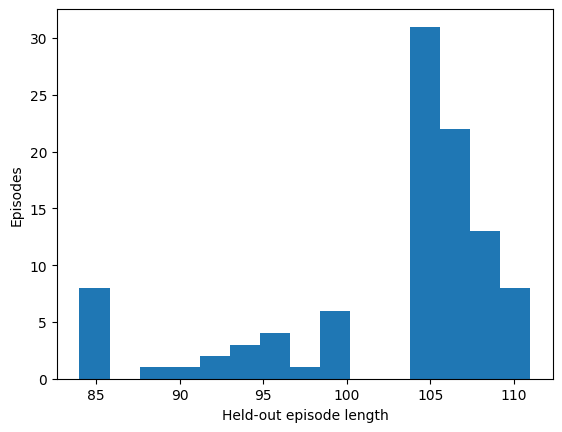

In [4]:
data=np.load(ROOT / "assets/source_data/approximation/lambda0.9_0.npz")
assert np.array_equal(data["seeds"],np.arange(100)+300000)
print("success",data["success"].mean(),"mean steps",data["lengths"].mean())
plt.hist(data["lengths"],bins=15);plt.xlabel("Held-out episode length");plt.ylabel("Episodes");plt.show()

Full fits: `decision-lab approximation --seed 0` (repeat seeds 1 and 2 where applicable). See [protocol](../docs/protocol.md), [results](../docs/results.md) and [references](../docs/references.md). These cells are numerical checks and evidence readers, not replacement training budgets.